# Evaluation Analysis: Reuse Strategies for nf-core/rnaseq on Kubernetes
Based on 5-sample experiments run under consistent conditions on the same node.
Energy = task pods only (windowed). Service pod overhead measured separately for S3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 130,
})

BASE    = '/home/sm/experiments/data'
METRICS = '/home/sm/experiments/metrics'
PLOTS   = '/home/sm/experiments/plots'
os.makedirs(PLOTS, exist_ok=True)

EXPERIMENTS = {
    'S1: No Reuse':       'S1_nextflow_rnaseq_U2_baseline_2026_04_02_23_01_07_3cb9d5ab/data',
    'S2: Index Reuse':    'Q_nextflow_rnaseq_concurrent_U2_index_shared_2026_03_31_18_06_18_fceb9ad6/data',
    'S3: Pod-Service':    'S1_nextflow_rnaseq_U2_podservice_2026_04_02_17_52_44_af5e8592/data',
}

TRACE_DIRS = {
    'S1: No Reuse':       ['user1_20260402_230117',          'user2_20260402_230117'],
    'S2: Index Reuse':    ['user1_reuse_20260331_180628',    'user2_reuse_20260331_180628'],
    'S3: Pod-Service':    ['user1_podservice_20260402_175254','user2_podservice_20260402_175254'],
}

# Verified corrected numbers (task pods only, windowed)
ENERGY = {
    'S1: No Reuse':       {'task': 347911, 'service':      0, 'duration': 105.2},
    'S2: Index Reuse':    {'task': 151892, 'service':      0, 'duration':  46.7},
    'S3: Pod-Service':    {'task': 336501, 'service': 115592, 'duration': 119.0},
}
for k in ENERGY:
    ENERGY[k]['total'] = ENERGY[k]['task'] + ENERGY[k]['service']

TASK_STATS = {
    'S1: No Reuse':       {'completed': 607, 'cached':   0, 'wall_u1': 98.2,  'wall_u2': 102.6},
    'S2: Index Reuse':    {'completed': 217, 'cached':   0, 'wall_u1': 43.1,  'wall_u2':  44.7},
    'S3: Pod-Service':    {'completed': 607, 'cached':   0, 'wall_u1': 117.0, 'wall_u2': 116.7},
}

COLORS = {
    'S1: No Reuse':       '#e74c3c',
    'S2: Index Reuse':    '#3498db',
    'S3: Pod-Service':    '#e67e22',
}
LABELS = list(EXPERIMENTS.keys())
print('Setup complete. Energy summary:')
s1 = ENERGY['S1: No Reuse']['task']
for n, e in ENERGY.items():
    saving = (s1 - e['task']) / s1 * 100
    print(f"  {n}: {e['task']:.0f} J task  {e['service']:.0f} J svc  {e['duration']:.1f} min  ({saving:+.1f}% vs S1 task)")

Setup complete. Energy summary:
  S1: No Reuse: 347911 J task  0 J svc  105.2 min  (+0.0% vs S1 task)
  S2: Index Reuse: 151892 J task  0 J svc  46.7 min  (+56.3% vs S1 task)
  S3: Pod-Service: 336501 J task  115592 J svc  119.0 min  (+3.3% vs S1 task)


## Figure 1 – Pipeline Duration per User
Shows the wall-clock time each user waits for results.

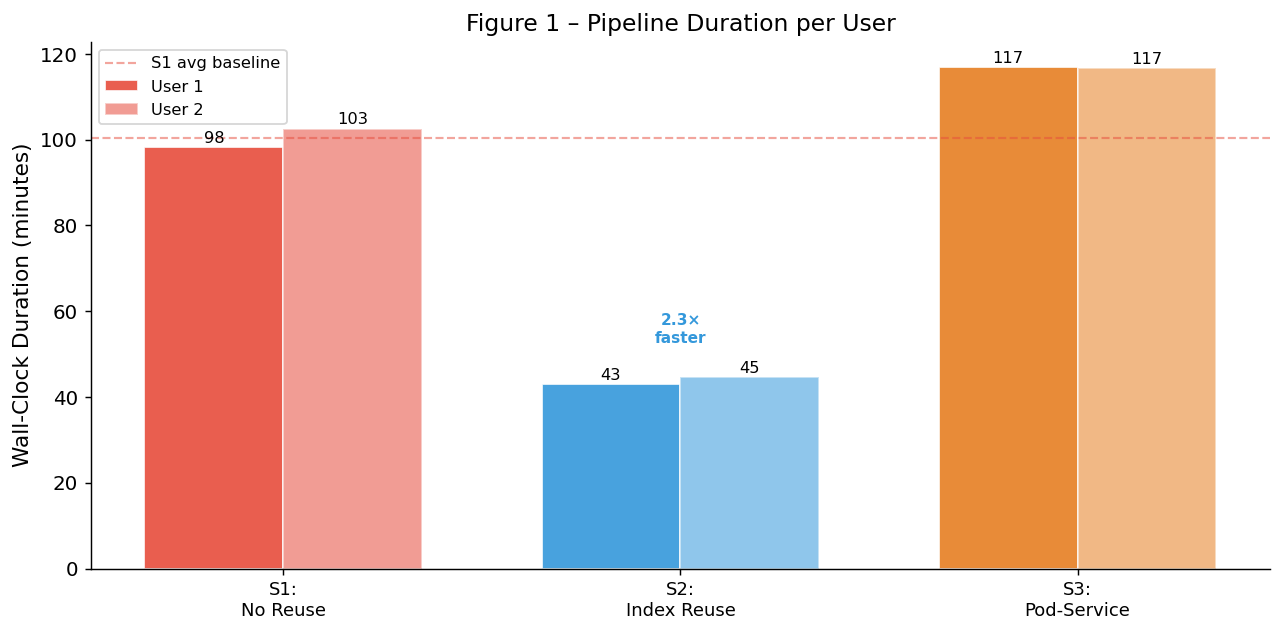

NameError: name 's2seq_avg' is not defined

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(LABELS))
w = 0.35

u1 = [TASK_STATS[n]['wall_u1'] for n in LABELS]
u2 = [TASK_STATS[n]['wall_u2'] for n in LABELS]

bars1 = ax.bar(x - w/2, u1, w, label='User 1', color=[COLORS[n] for n in LABELS], edgecolor='white', alpha=0.9)
bars2 = ax.bar(x + w/2, u2, w, label='User 2', color=[COLORS[n] for n in LABELS], edgecolor='white', alpha=0.55)

for bar, val in zip(bars1, u1):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{val:.0f}', ha='center', fontsize=9)
for bar, val in zip(bars2, u2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{val:.0f}', ha='center', fontsize=9)

# Speedup annotations
s1_avg = (TASK_STATS['S1: No Reuse']['wall_u1'] + TASK_STATS['S1: No Reuse']['wall_u2']) / 2
for i, name in enumerate(LABELS):
    if name == 'S1: No Reuse': continue
    avg = (TASK_STATS[name]['wall_u1'] + TASK_STATS[name]['wall_u2']) / 2
    speedup = s1_avg / avg
    if speedup > 1:
        ax.text(i, max(u1[i], u2[i]) + 8, f'{speedup:.1f}×\nfaster', ha='center',
                fontsize=8.5, color=COLORS[name], fontweight='bold')

ax.axhline(y=s1_avg, color='#e74c3c', linestyle='--', linewidth=1.2, alpha=0.5, label='S1 avg baseline')
ax.set_xticks(x)
ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_ylabel('Wall-Clock Duration (minutes)')
ax.set_title('Figure 1 – Pipeline Duration per User')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig1_duration.pdf', bbox_inches='tight')
plt.show()

#s2seq_avg = (TASK_STATS['S2-seq: Full Reuse']['wall_u1'] + TASK_STATS['S2-seq: Full Reuse']['wall_u2']) / 2
print(f'S2-seq avg duration: {s2seq_avg:.1f} min  →  {s1_avg/s2seq_avg:.1f}× faster than S1')
print(f'S2-index avg: {(TASK_STATS["S2: Index Reuse"]["wall_u1"]+TASK_STATS["S2: Index Reuse"]["wall_u2"])/2:.1f} min  →  {s1_avg/((TASK_STATS["S2: Index Reuse"]["wall_u1"]+TASK_STATS["S2: Index Reuse"]["wall_u2"])/2):.1f}× faster')

## Figure 2 – Cached vs Computed Tasks
Shows reuse in action: S2-seq's second user skips 218 of 219 tasks.

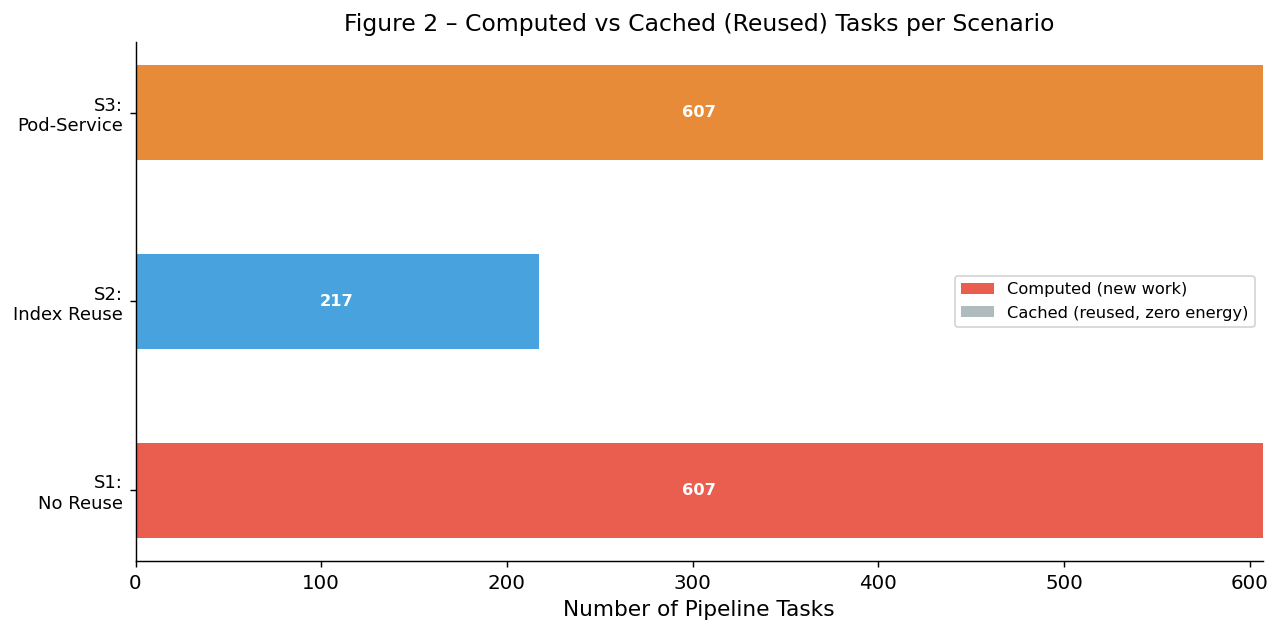

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(LABELS))
completed = [TASK_STATS[n]['completed'] for n in LABELS]
cached    = [TASK_STATS[n]['cached']    for n in LABELS]

ax.barh(y, completed, 0.5, label='Computed (new work)', color=[COLORS[n] for n in LABELS], alpha=0.9)
ax.barh(y, cached,    0.5, left=completed, label='Cached (reused, zero energy)', color='#95a5a6', alpha=0.75)

for i, (c, ca) in enumerate(zip(completed, cached)):
    total = c + ca
    if ca > 0:
        ax.text(total + 5, i, f'{ca/(c+ca)*100:.0f}% reused ({ca} tasks)',
                va='center', fontsize=10, color='#27ae60', fontweight='bold')
    ax.text(c/2, i, str(c), va='center', ha='center', fontsize=9, color='white', fontweight='bold')

ax.set_yticks(y)
ax.set_yticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_xlabel('Number of Pipeline Tasks')
ax.set_title('Figure 2 – Computed vs Cached (Reused) Tasks per Scenario')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig2_cached_tasks.pdf', bbox_inches='tight')
plt.show()

## Figure 3 – Task Pod Count (Scheduling Overhead)
Fewer pods = less Kubernetes scheduler load, faster startup, lower overhead.

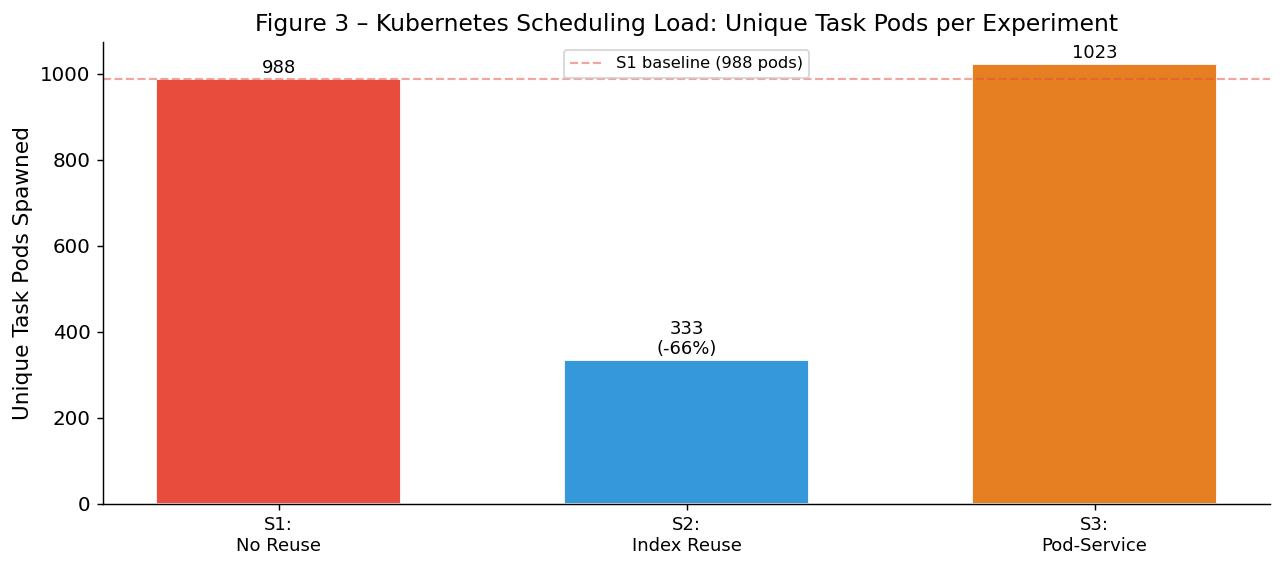

KeyError: 'S2-seq: Full Reuse'

In [5]:
pod_counts = {}
for name in LABELS:
    path = os.path.join(BASE, EXPERIMENTS[name], 'kepler_pod_cpu_power_joules_raw.csv')
    if not os.path.exists(path): pod_counts[name] = 0; continue
    df = pd.read_csv(path)
    pod_col = next((c for c in df.columns if 'pod_name' in c.lower()), None)
    is_task = df[pod_col].astype(str).str.startswith('nf-')
    pod_counts[name] = df[is_task][pod_col].nunique()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(range(len(LABELS)), [pod_counts[n] for n in LABELS],
              color=[COLORS[n] for n in LABELS], edgecolor='white', width=0.6)
s1_pods = pod_counts['S1: No Reuse']
for bar, val, name in zip(bars, [pod_counts[n] for n in LABELS], LABELS):
    pct = (1 - val/s1_pods)*100 if val < s1_pods else 0
    label = f'{val}' + (f'\n(-{pct:.0f}%)' if pct > 0 else '')
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5, label,
            ha='center', va='bottom', fontsize=10)

ax.axhline(y=s1_pods, color='#e74c3c', linestyle='--', linewidth=1.2, alpha=0.5, label=f'S1 baseline ({s1_pods} pods)')
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_ylabel('Unique Task Pods Spawned')
ax.set_title('Figure 3 – Kubernetes Scheduling Load: Unique Task Pods per Experiment')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig3_pod_count.pdf', bbox_inches='tight')
plt.show()
print('Pod reduction S2-seq vs S1:', f'{(1-pod_counts["S2-seq: Full Reuse"]/s1_pods)*100:.0f}%')
print('Pod reduction S2-index vs S1:', f'{(1-pod_counts["S2: Index Reuse"]/s1_pods)*100:.0f}%')

## Figure 4 – Task Pod Energy Consumption
Task-only energy (service pods excluded). All reuse strategies reduce task pod energy.

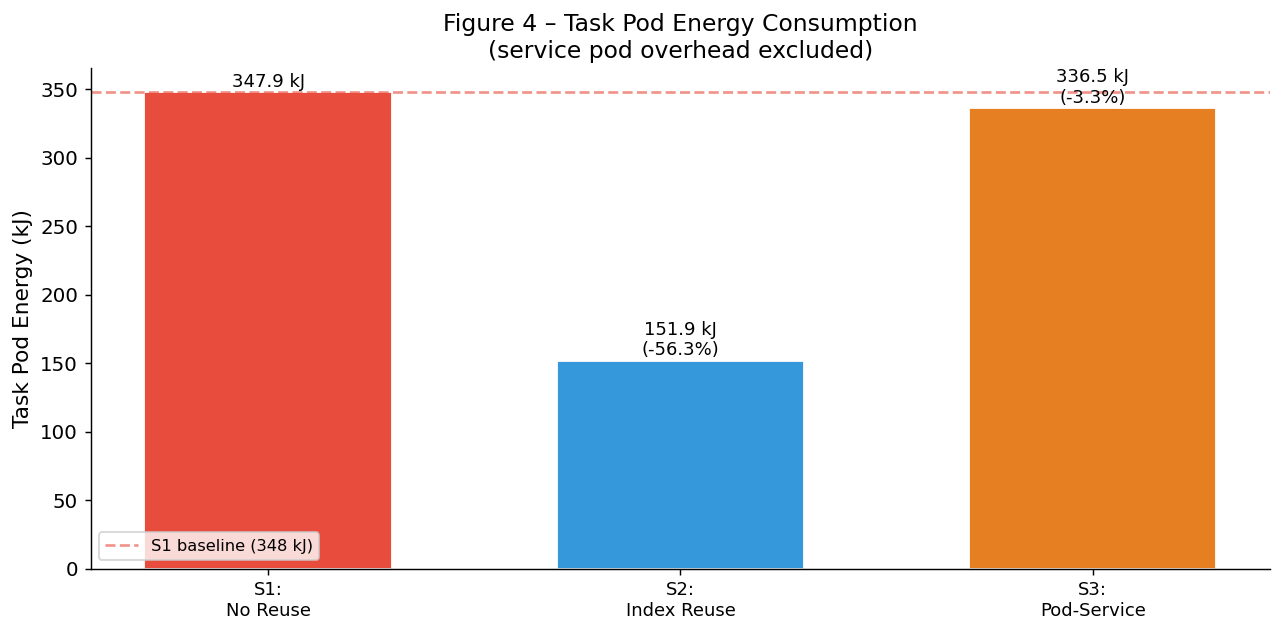

In [6]:
s1_task = ENERGY['S1: No Reuse']['task']
task_vals = [ENERGY[n]['task']/1000 for n in LABELS]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(LABELS)), task_vals,
              color=[COLORS[n] for n in LABELS], edgecolor='white', width=0.6)

for bar, val, name in zip(bars, task_vals, LABELS):
    saving = (s1_task - ENERGY[name]['task']) / s1_task * 100
    label = f'{val:.1f} kJ'
    if saving > 0:
        label += f'\n(-{saving:.1f}%)'
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
            label, ha='center', va='bottom', fontsize=10)

ax.axhline(y=s1_task/1000, color='#e74c3c', linestyle='--', linewidth=1.5,
           alpha=0.6, label=f'S1 baseline ({s1_task/1000:.0f} kJ)')
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_ylabel('Task Pod Energy (kJ)')
ax.set_title('Figure 4 – Task Pod Energy Consumption\n(service pod overhead excluded)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig4_task_energy.pdf', bbox_inches='tight')
plt.show()

## Figure 5 – Total Energy with Service Pod Overhead
For S3 only: adds persistent service pod idle energy on top of task energy.

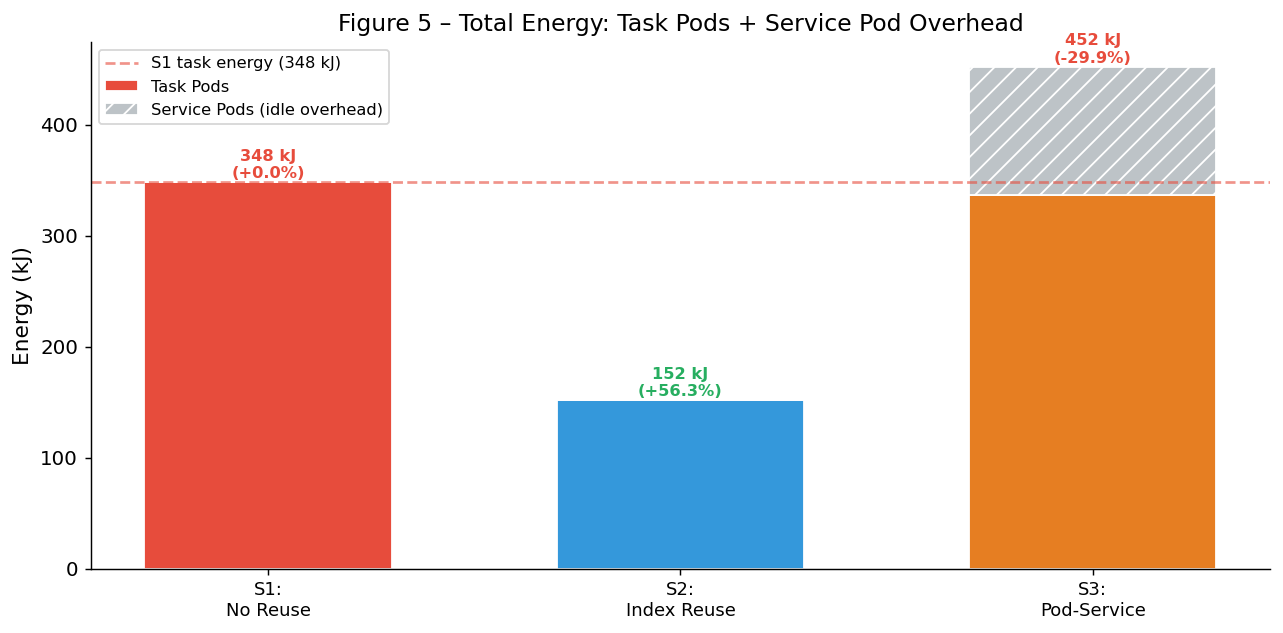

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(LABELS))
task_vals = [ENERGY[n]['task']/1000  for n in LABELS]
svc_vals  = [ENERGY[n]['service']/1000 for n in LABELS]

p1 = ax.bar(x, task_vals, 0.6, label='Task Pods',
            color=[COLORS[n] for n in LABELS], edgecolor='white')
p2 = ax.bar(x, svc_vals,  0.6, bottom=task_vals,
            label='Service Pods (idle overhead)', color='#bdc3c7', edgecolor='white', hatch='//')

for i, (t, s) in enumerate(zip(task_vals, svc_vals)):
    total = t + s
    s1_total = ENERGY['S1: No Reuse']['task'] / 1000
    saving = (s1_total - total) / s1_total * 100
    colour = '#27ae60' if saving > 0 else '#e74c3c'
    ax.text(i, total + 1, f'{total:.0f} kJ\n({saving:+.1f}%)',
            ha='center', va='bottom', fontsize=9, color=colour, fontweight='bold')

ax.axhline(y=ENERGY['S1: No Reuse']['task']/1000, color='#e74c3c',
           linestyle='--', linewidth=1.5, alpha=0.6,
           label=f'S1 task energy ({ENERGY["S1: No Reuse"]["task"]/1000:.0f} kJ)')
ax.set_xticks(x)
ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_ylabel('Energy (kJ)')
ax.set_title('Figure 5 – Total Energy: Task Pods + Service Pod Overhead')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig5_total_energy.pdf', bbox_inches='tight')
plt.show()

## Figure 6 – S3 Deep Dive: Service Overhead vs Scale-to-Zero Benefit
Compares always-on (measured) vs theoretical scale-to-zero service energy.

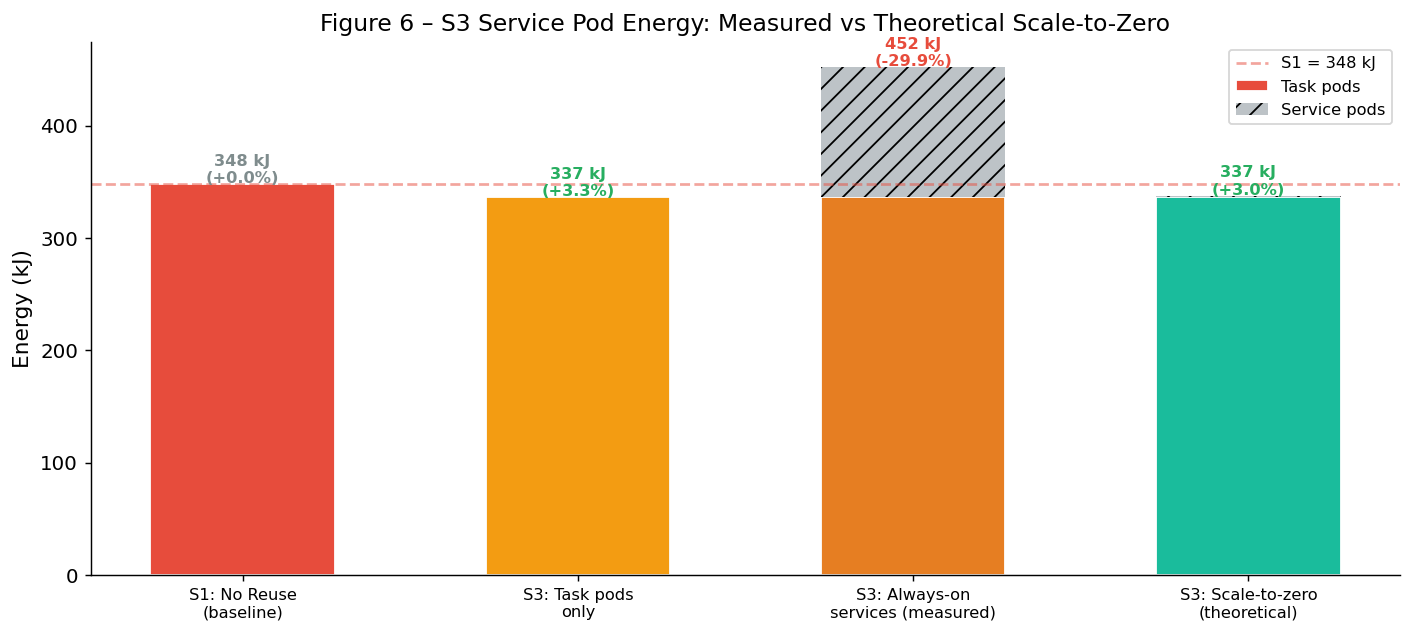

Service power: 16.2 W
Active time: 60 s  →  theoretical service energy: 971 J
S3 scale-to-zero total: 337.5 kJ  vs S1: 347.9 kJ
S3 scale-to-zero saving: +3.0%


In [8]:
# Measured service power and theoretical active-only energy
s3_svc_energy    = 115592   # J (measured, always-on)
s3_duration_s    = 119 * 60 # seconds
svc_power_w      = s3_svc_energy / s3_duration_s   # avg watts
n_requests       = 5 * 2    # 5 samples × 2 steps (featureCounts + StringTie) per user = 10 per user, 2 users
active_time_s    = n_requests * 6  # 6 seconds per service call
svc_theoretical  = svc_power_w * active_time_s

s3_task          = ENERGY['S3: Pod-Service']['task']
s1_task          = ENERGY['S1: No Reuse']['task']

scenarios = {
    'S1: No Reuse\n(baseline)':         {'task': s1_task,   'service': 0},
    'S3: Task pods\nonly':              {'task': s3_task,   'service': 0},
    'S3: Always-on\nservices (measured)':{'task': s3_task,  'service': s3_svc_energy},
    'S3: Scale-to-zero\n(theoretical)': {'task': s3_task,   'service': svc_theoretical},
}

fig, ax = plt.subplots(figsize=(11, 5))
colors4 = ['#e74c3c', '#f39c12', '#e67e22', '#1abc9c']
x = np.arange(len(scenarios))
task_v = [v['task']/1000  for v in scenarios.values()]
svc_v  = [v['service']/1000 for v in scenarios.values()]

ax.bar(x, task_v, 0.55, label='Task pods', color=colors4, edgecolor='white')
ax.bar(x, svc_v,  0.55, bottom=task_v, label='Service pods', color='#bdc3c7', hatch='//')

for i, (t, s) in enumerate(zip(task_v, svc_v)):
    total = t + s
    saving = (s1_task/1000 - total) / (s1_task/1000) * 100
    col = '#27ae60' if saving > 0 else ('#e74c3c' if saving < -1 else '#7f8c8d')
    ax.text(i, total+1, f'{total:.0f} kJ\n({saving:+.1f}%)',
            ha='center', fontsize=9, color=col, fontweight='bold')

ax.axhline(y=s1_task/1000, color='#e74c3c', linestyle='--',
           linewidth=1.5, alpha=0.5, label=f'S1 = {s1_task/1000:.0f} kJ')
ax.set_xticks(x)
ax.set_xticklabels(list(scenarios.keys()), fontsize=9)
ax.set_ylabel('Energy (kJ)')
ax.set_title('Figure 6 – S3 Service Pod Energy: Measured vs Theoretical Scale-to-Zero')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig6_s3_scaleto0.pdf', bbox_inches='tight')
plt.show()

print(f'Service power: {svc_power_w:.1f} W')
print(f'Active time: {active_time_s} s  →  theoretical service energy: {svc_theoretical:.0f} J')
print(f'S3 scale-to-zero total: {(s3_task+svc_theoretical)/1000:.1f} kJ  vs S1: {s1_task/1000:.1f} kJ')
print(f'S3 scale-to-zero saving: {(s1_task-(s3_task+svc_theoretical))/s1_task*100:+.1f}%')

## Figure 7 – Throughput: Tasks per Minute
Reuse strategies process more samples in less time.

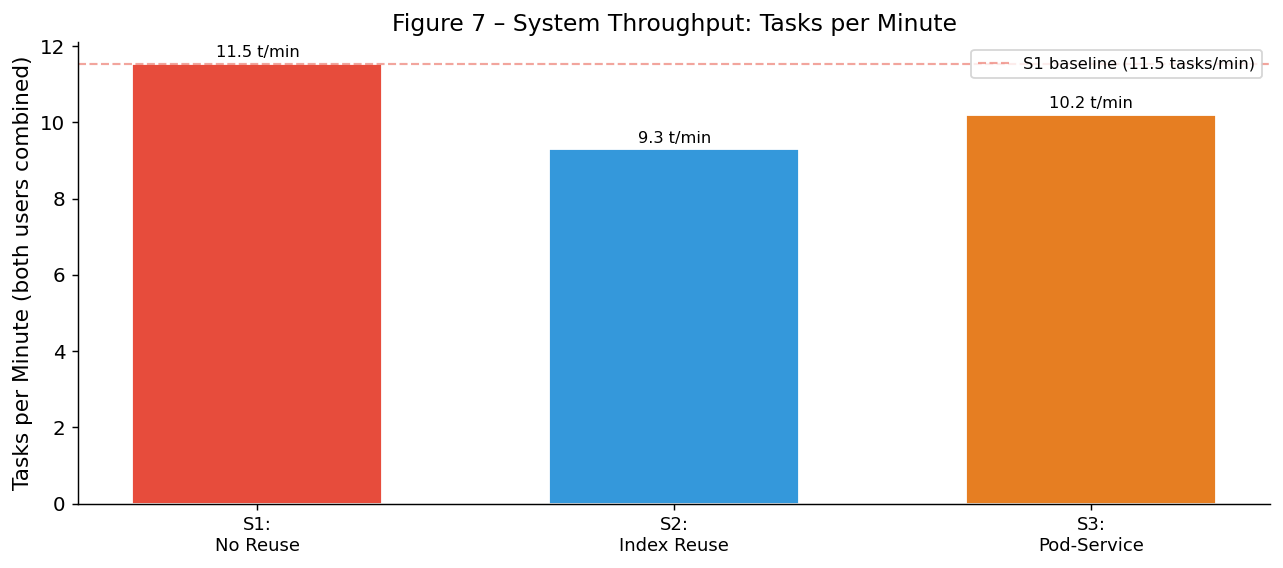

In [9]:
# Tasks per minute (both users combined, wall-clock from energy window)
durations = {
    'S1: No Reuse':       105.2,
    'S2-seq: Full Reuse':  25.3,
    'S2: Index Reuse':     46.7,
    'S3: Pod-Service':    119.0,
}
total_tasks_2users = {
    'S1: No Reuse':       607 + 607,
    'S2-seq: Full Reuse': 219 + 219,   # both users complete 219 tasks (user2 via cache)
    'S2: Index Reuse':    217 + 217,
    'S3: Pod-Service':    607 + 607,
}
throughput = {n: total_tasks_2users[n] / durations[n] for n in LABELS}

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(range(len(LABELS)), [throughput[n] for n in LABELS],
              color=[COLORS[n] for n in LABELS], edgecolor='white', width=0.6)

s1_tpt = throughput['S1: No Reuse']
for bar, val, name in zip(bars, [throughput[n] for n in LABELS], LABELS):
    improvement = (val - s1_tpt) / s1_tpt * 100
    label = f'{val:.1f} t/min'
    if improvement > 0:
        label += f'\n(+{improvement:.0f}%)'
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
            label, ha='center', va='bottom', fontsize=9)

ax.axhline(y=s1_tpt, color='#e74c3c', linestyle='--', linewidth=1.2, alpha=0.5,
           label=f'S1 baseline ({s1_tpt:.1f} tasks/min)')
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=10)
ax.set_ylabel('Tasks per Minute (both users combined)')
ax.set_title('Figure 7 – System Throughput: Tasks per Minute')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig7_throughput.pdf', bbox_inches='tight')
plt.show()

## Figure 8 – Network I/O Savings
Cached tasks avoid re-reading inputs, reducing network transfer.

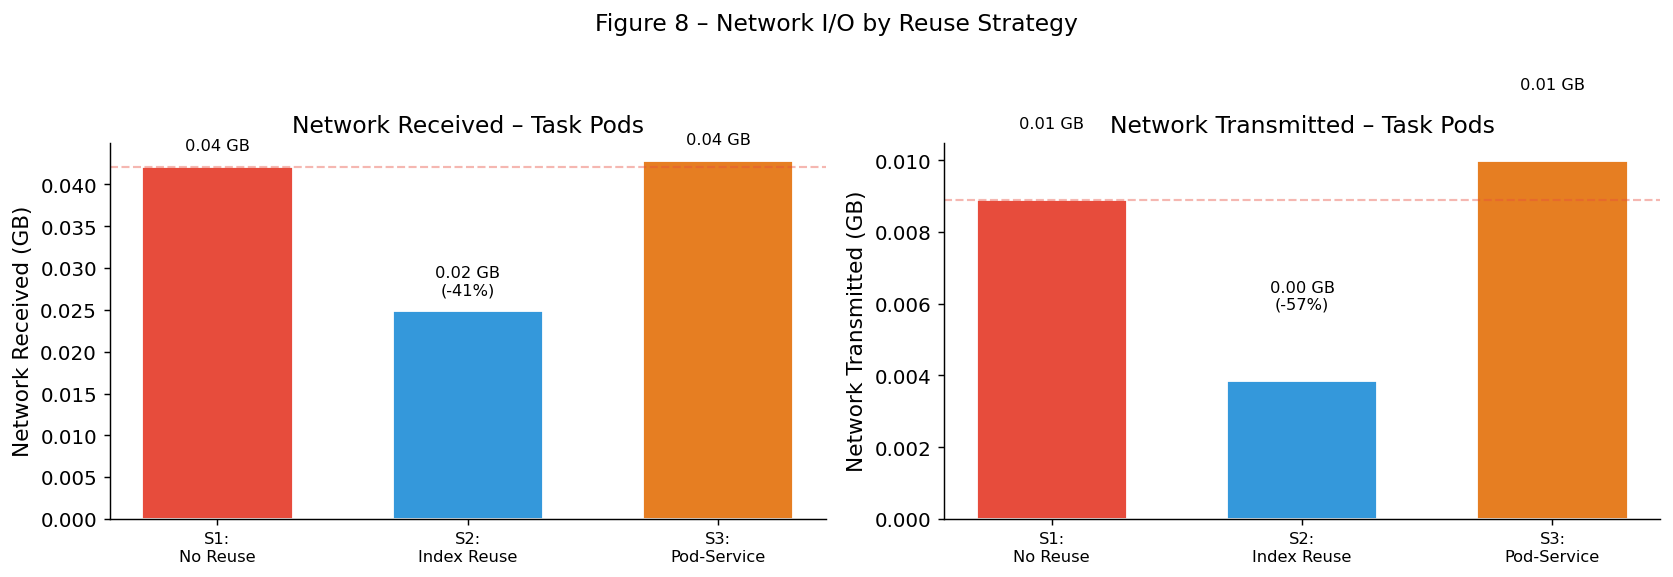

In [10]:
def load_network(exp_name, direction='receive'):
    fname = f'pod_network_{direction}_bytes.csv'
    path = os.path.join(BASE, EXPERIMENTS[exp_name], fname)
    if not os.path.exists(path): return 0
    df = pd.read_csv(path)
    val = [c for c in df.columns if 'byte' in c.lower() or c=='value'][-1]
    df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)
    pod_col = next((c for c in df.columns if 'pod_name' in c.lower()), None)
    if pod_col:
        is_task = df[pod_col].astype(str).str.startswith('nf-')
        return df[is_task][val].sum() / 1e9
    return df[val].sum() / 1e9

net_rx = {n: load_network(n, 'receive')  for n in LABELS}
net_tx = {n: load_network(n, 'transmit') for n in LABELS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, data, title in [(axes[0], net_rx, 'Received'), (axes[1], net_tx, 'Transmitted')]:
    bars = ax.bar(range(len(LABELS)), [data[n] for n in LABELS],
                  color=[COLORS[n] for n in LABELS], edgecolor='white', width=0.6)
    s1_val = data['S1: No Reuse']
    for bar, val, name in zip(bars, [data[n] for n in LABELS], LABELS):
        if val > 0:
            saving = (s1_val - val) / s1_val * 100 if s1_val > 0 else 0
            label = f'{val:.2f} GB'
            if saving > 5: label += f'\n(-{saving:.0f}%)'
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                    label, ha='center', fontsize=9)
    ax.axhline(y=s1_val, color='#e74c3c', linestyle='--', alpha=0.4, linewidth=1.2)
    ax.set_xticks(range(len(LABELS)))
    ax.set_xticklabels([l.replace(': ', ':\n') for l in LABELS], fontsize=9)
    ax.set_ylabel(f'Network {title} (GB)')
    ax.set_title(f'Network {title} – Task Pods')

plt.suptitle('Figure 8 – Network I/O by Reuse Strategy', fontsize=13)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig8_network.pdf', bbox_inches='tight')
plt.show()

## Figure 9 – CPU Power Timeline
Shows when pipelines are active — S2-seq finishes 4× sooner.

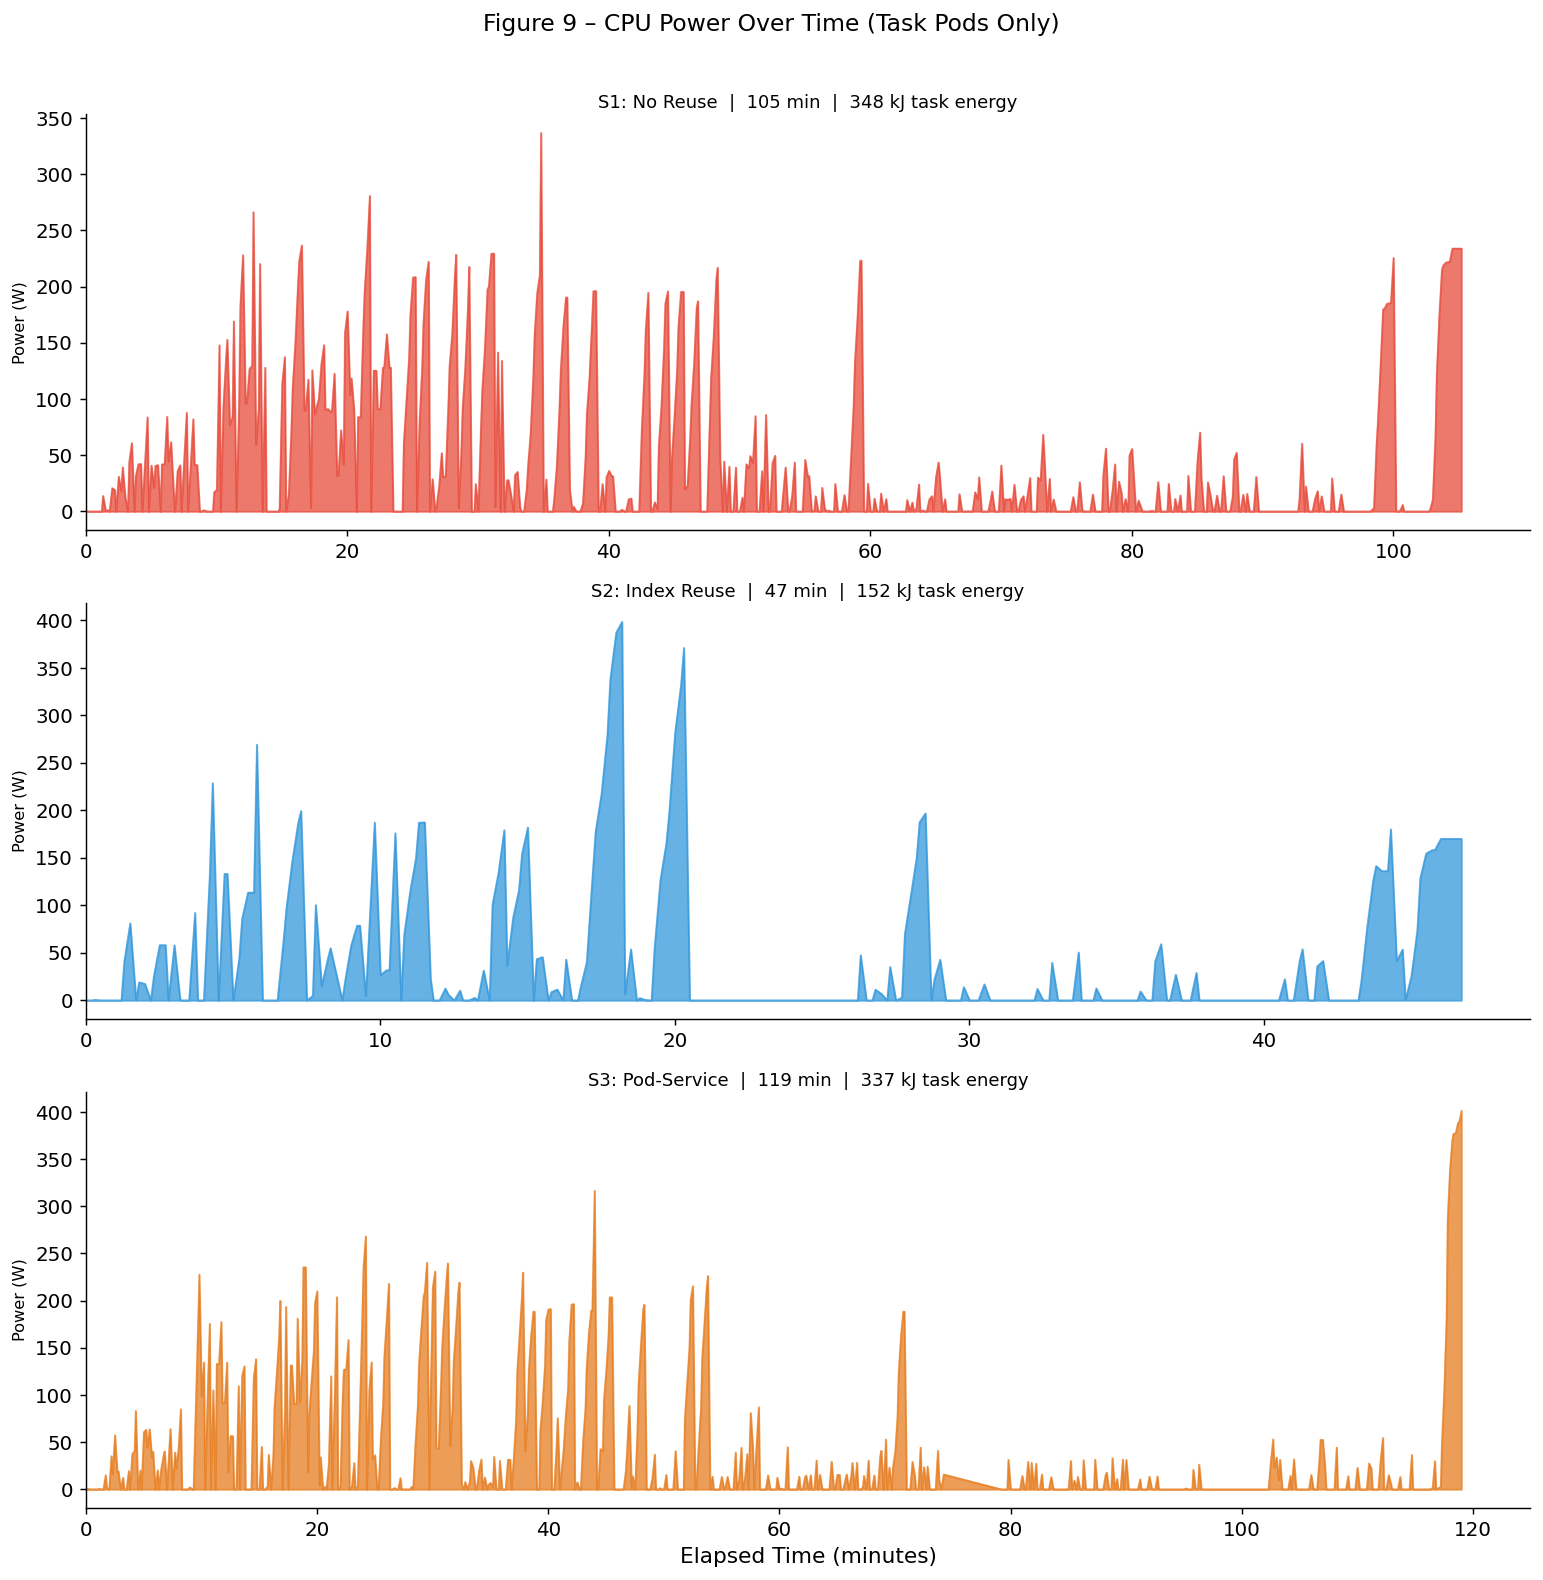

Figure 9 done


In [11]:
fig, axes = plt.subplots(len(LABELS), 1, figsize=(12, 12), sharex=False)

for ax, name in zip(axes, LABELS):
    path = os.path.join(BASE, EXPERIMENTS[name], 'kepler_pod_cpu_power_joules_raw.csv')
    if not os.path.exists(path):
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center')
        ax.set_title(name)
        continue

    df = pd.read_csv(path)
    df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
    df = df.dropna(subset=['ts'])
    df['kepler_pod_cpu_power_joules_raw'] = pd.to_numeric(
        df['kepler_pod_cpu_power_joules_raw'], errors='coerce').fillna(0)

    is_task = df['pod_name'].astype(str).str.startswith('nf-')
    df_t = df[is_task].copy()
    if df_t.empty:
        ax.text(0.5, 0.5, 'No task pods found', transform=ax.transAxes, ha='center')
        ax.set_title(name); continue

    t0 = df_t['ts'].min()
    df_t['elapsed'] = (df_t['ts'] - t0).dt.total_seconds() / 60

    # Derive watts: joule diff / time diff per pod
    df_t = df_t.sort_values(['pod_name', 'ts'])
    df_t['joule_diff'] = df_t.groupby('pod_name')['kepler_pod_cpu_power_joules_raw'].diff().fillna(0).clip(lower=0)
    df_t['time_diff_s'] = df_t.groupby('pod_name')['ts'].diff().dt.total_seconds().fillna(15).clip(lower=1)
    df_t['watts'] = df_t['joule_diff'] / df_t['time_diff_s']

    df_t['elapsed_bin'] = df_t['elapsed'].round(1)
    grp = df_t.groupby('elapsed_bin')['watts'].sum().reset_index()

    ax.fill_between(grp['elapsed_bin'], grp['watts'], color=COLORS[name], alpha=0.75)
    ax.plot(grp['elapsed_bin'], grp['watts'], color=COLORS[name], linewidth=0.8, alpha=0.5)
    ax.set_xlim(left=0)
    ax.set_ylabel('Power (W)', fontsize=9)
    ax.set_title(
        f'{name}  |  {ENERGY[name]["duration"]:.0f} min  |  {ENERGY[name]["task"]/1000:.0f} kJ task energy',
        fontsize=10, pad=3
    )

axes[-1].set_xlabel('Elapsed Time (minutes)')
plt.suptitle('Figure 9 – CPU Power Over Time (Task Pods Only)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig9_power_timeline.pdf', bbox_inches='tight')
plt.show()
print("Figure 9 done")


## Figure 10 – Summary: Energy vs Duration Scatter
Shows the Pareto frontier — S2-seq is best on both axes simultaneously.

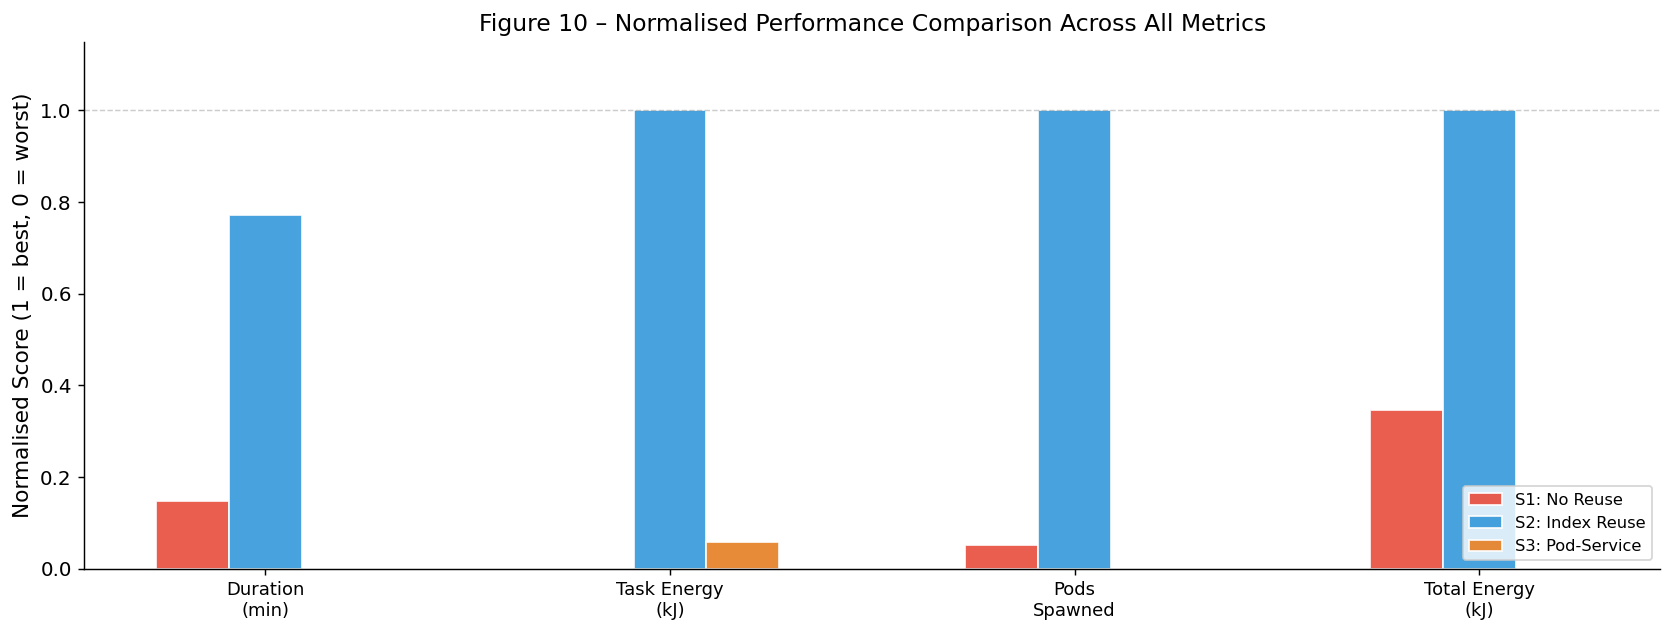

Figure 10 done


In [12]:
# Normalised multi-metric bar chart (lower original = taller bar = better)
metrics_raw = {
    'Duration\n(min)':    {'S1: No Reuse': 105.2, 'S2-seq: Full Reuse': 25.3, 'S2: Index Reuse': 46.7, 'S3: Pod-Service': 119.0},
    'Task Energy\n(kJ)':  {n: ENERGY[n]['task']/1000 for n in LABELS},
    'Pods\nSpawned':      {n: pod_counts.get(n, 0) for n in LABELS},
    'Total Energy\n(kJ)': {n: ENERGY[n]['total']/1000 for n in LABELS},
}

metric_names = list(metrics_raw.keys())
x = np.arange(len(metric_names))
w = 0.18
offsets = np.linspace(-(len(LABELS)-1)/2*w, (len(LABELS)-1)/2*w, len(LABELS))

fig, ax = plt.subplots(figsize=(13, 5))

for offset, name in zip(offsets, LABELS):
    vals = []
    for m in metric_names:
        mn = min(metrics_raw[m].values())
        mx = max(metrics_raw[m].values())
        # Normalise: 1 = best (lowest original value), 0 = worst
        norm = 1 - (metrics_raw[m][name] - mn) / (mx - mn) if mx != mn else 0.5
        vals.append(norm)
    bars = ax.bar(x + offset, vals, w, label=name,
                  color=COLORS[name], edgecolor='white', alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=10)
ax.set_ylabel('Normalised Score (1 = best, 0 = worst)')
ax.set_title('Figure 10 – Normalised Performance Comparison Across All Metrics')
ax.set_ylim(0, 1.15)
ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.4)
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{PLOTS}/fig10_comparison.pdf', bbox_inches='tight')
plt.show()
print("Figure 10 done")


## Summary Table

In [13]:
s1_task = ENERGY['S1: No Reuse']['task']
s1_dur  = ENERGY['S1: No Reuse']['duration']

rows = []
for name in LABELS:
    e = ENERGY[name]
    ts = TASK_STATS[name]
    rows.append({
        'Scenario':            name,
        'Duration (min)':      f"{e['duration']:.1f}",
        'vs S1 Duration':      f"{(s1_dur-e['duration'])/s1_dur*100:+.1f}%",
        'Task Energy (kJ)':    f"{e['task']/1000:.1f}",
        'vs S1 Task Energy':   f"{(s1_task-e['task'])/s1_task*100:+.1f}%",
        'Svc Overhead (kJ)':   f"{e['service']/1000:.1f}",
        'Total Energy (kJ)':   f"{e['total']/1000:.1f}",
        'Cached Tasks':        ts['cached'],
        'Throughput (t/min)':  f"{(ts['completed']*2)/e['duration']:.1f}",
    })

df_sum = pd.DataFrame(rows).set_index('Scenario')
print(df_sum.to_string())
df_sum.to_csv(f'{PLOTS}/summary_table.csv')
print('\nSaved to:', f'{PLOTS}/summary_table.csv')

                Duration (min) vs S1 Duration Task Energy (kJ) vs S1 Task Energy Svc Overhead (kJ) Total Energy (kJ)  Cached Tasks Throughput (t/min)
Scenario                                                                                                                                             
S1: No Reuse             105.2          +0.0%            347.9             +0.0%               0.0             347.9             0               11.5
S2: Index Reuse           46.7         +55.6%            151.9            +56.3%               0.0             151.9             0                9.3
S3: Pod-Service          119.0         -13.1%            336.5             +3.3%             115.6             452.1             0               10.2

Saved to: /home/sm/experiments/plots/summary_table.csv


In [14]:
# Run this in your notebook first to debug
import os
BASE = '/home/sm/experiments/data'
EXPERIMENTS = {
    'S1: No Reuse': 'S1_nextflow_rnaseq_U2_baseline_2026_04_02_23_01_07_3cb9d5ab/data',
}

import pandas as pd
for name, d in EXPERIMENTS.items():
    for fname in ['kepler_all_pod_cpu_power_watts.csv', 'kepler_pod_cpu_power_joules_raw.csv']:
        path = os.path.join(BASE, d, fname)
        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"{fname}:")
            print(f"  columns: {list(df.columns)}")
            print(f"  first row: {df.iloc[0].to_dict()}")
            print()

kepler_all_pod_cpu_power_watts.csv:
  columns: ['timestamp', 'timestamp.1', 'kepler_all_pod_cpu_power_watts', 'layer', 'unit', 'treatment']
  first row: {'timestamp': '2026-04-02 21:01:07.691999912+00:00', 'timestamp.1': 1775163667.692, 'kepler_all_pod_cpu_power_watts': 0.0, 'layer': 'cluster', 'unit': 'watts', 'treatment': 'NoTreatment'}

kepler_pod_cpu_power_joules_raw.csv:
  columns: ['timestamp', '__name__', 'app_kubernetes_io_component', 'app_kubernetes_io_managed_by', 'app_kubernetes_io_name', 'app_kubernetes_io_version', 'container_id', 'container_name', 'container_namespace', 'helm_sh_chart', 'instance', 'job', 'mode', 'namespace', 'node', 'pod_name', 'service', 'timestamp.1', 'kepler_pod_cpu_power_joules_raw', 'layer', 'unit', 'treatment']
  first row: {'timestamp': '2026-04-02 21:27:17.691999912+00:00', '__name__': 'kepler_container_joules_total', 'app_kubernetes_io_component': 'exporter', 'app_kubernetes_io_managed_by': 'Helm', 'app_kubernetes_io_name': 'kepler-old', 'app_ku